**#30DayMapChallenge – Day 9: Urban–Rural**

**The Invisible City – Mapping Austria's Settlement Structure**

Where does the city end and the countryside begin? For Day 9 of the #30DayMapChallenge, I wanted to explore the urban–rural divide without relying on administrative boundaries, population figures, or conventional settlement classifications. Instead, I used Austria's building footprints and the official 250-metre grid from Statistics Austria to examine the spatial morphology of settlements. By combining building density, built-up area, and distances between neighbouring buildings, I created a continuous urbanity index that describes how intensely each part of the country is built up.

The resulting map reveals Austria's settlement structure as an intricate network of dense urban centres, smaller towns, villages, and scattered buildings. Vienna and the other major cities stand out as dark concentrations, while valleys and transport corridors emerge as fine, branching patterns connecting settlements across the country. The Alpine regions, by contrast, remain largely open, with development concentrated along accessible valleys. What I find particularly interesting is how clearly the geography of Austria becomes visible through its buildings alone. Rather than drawing a sharp line between urban and rural, the map illustrates a gradual transition between different forms of settlement – reminding us that the distinction between city and countryside is often far less clear than our administrative maps suggest.

#30DayMapChallenge #Day9 #UrbanRural #Austria #SettlementPatterns #SpatialAnalysis #GIS #UrbanMorphology #Cartography

In [1]:
import geopandas as gpd
import numpy as np
from scipy.spatial import cKDTree

gdf = gpd.read_file("E:\\LOKAL_GIS\\AT\\DLM\\DLM_8000_BAUWERK_20260323.gpkg", layer="BWK_8100_BAUWERK_F")
# GeoDataFrame mit Gebäuden
gdf = gdf.to_crs(31287)

coords = np.column_stack([
    gdf.geometry.centroid.x,
    gdf.geometry.centroid.y
])

tree = cKDTree(coords)

# k=2, da der erste Nachbar der Punkt selbst ist
distances, indices = tree.query(coords, k=2)

gdf["nn_distance"] = distances[:, 1]

In [2]:
import geopandas as gpd
import numpy as np
from shapely.geometry import box

resolution = 1000

xmin, ymin, xmax, ymax = gdf.total_bounds

xs = np.arange(xmin, xmax, resolution)
ys = np.arange(ymin, ymax, resolution)

grid = gpd.GeoDataFrame(
    geometry=[
        box(x, y, x + resolution, y + resolution)
        for x in xs
        for y in ys
    ],
    crs=gdf.crs
)

# Gebäudezentroide räumlich zuordnen
buildings = gdf.copy()
buildings.geometry = buildings.geometry.centroid

joined = gpd.sjoin(
    buildings,
    grid,
    how="inner",
    predicate="within"
)

counts = joined.groupby("index_right").size()

grid["n_buildings"] = (
    grid.index.map(counts).fillna(0).astype(int)
)

grid["density"] = (
        grid["n_buildings"] /
        (grid.geometry.area / 1e6)
)

In [3]:
mean_nn = joined.groupby("index_right")[
    "nn_distance"
].mean()

grid["mean_nn"] = grid.index.map(mean_nn)


# Normalisierung mit robusten Quantilen
def normalize(series):
    lo = series.quantile(0.05)
    hi = series.quantile(0.95)

    if hi <= lo:
        return series * 0

    return ((series - lo) / (hi - lo)).clip(0, 1)


grid["density_norm"] = normalize(
    np.log1p(grid["density"])
)

grid["nn_norm"] = 1 - normalize(
    grid["mean_nn"]
)

grid["urbanity"] = (
        0.5 * grid["density_norm"] +
        0.5 * grid["nn_norm"].fillna(0)
)

grid.loc[grid["n_buildings"] == 0, "urbanity"] = 0

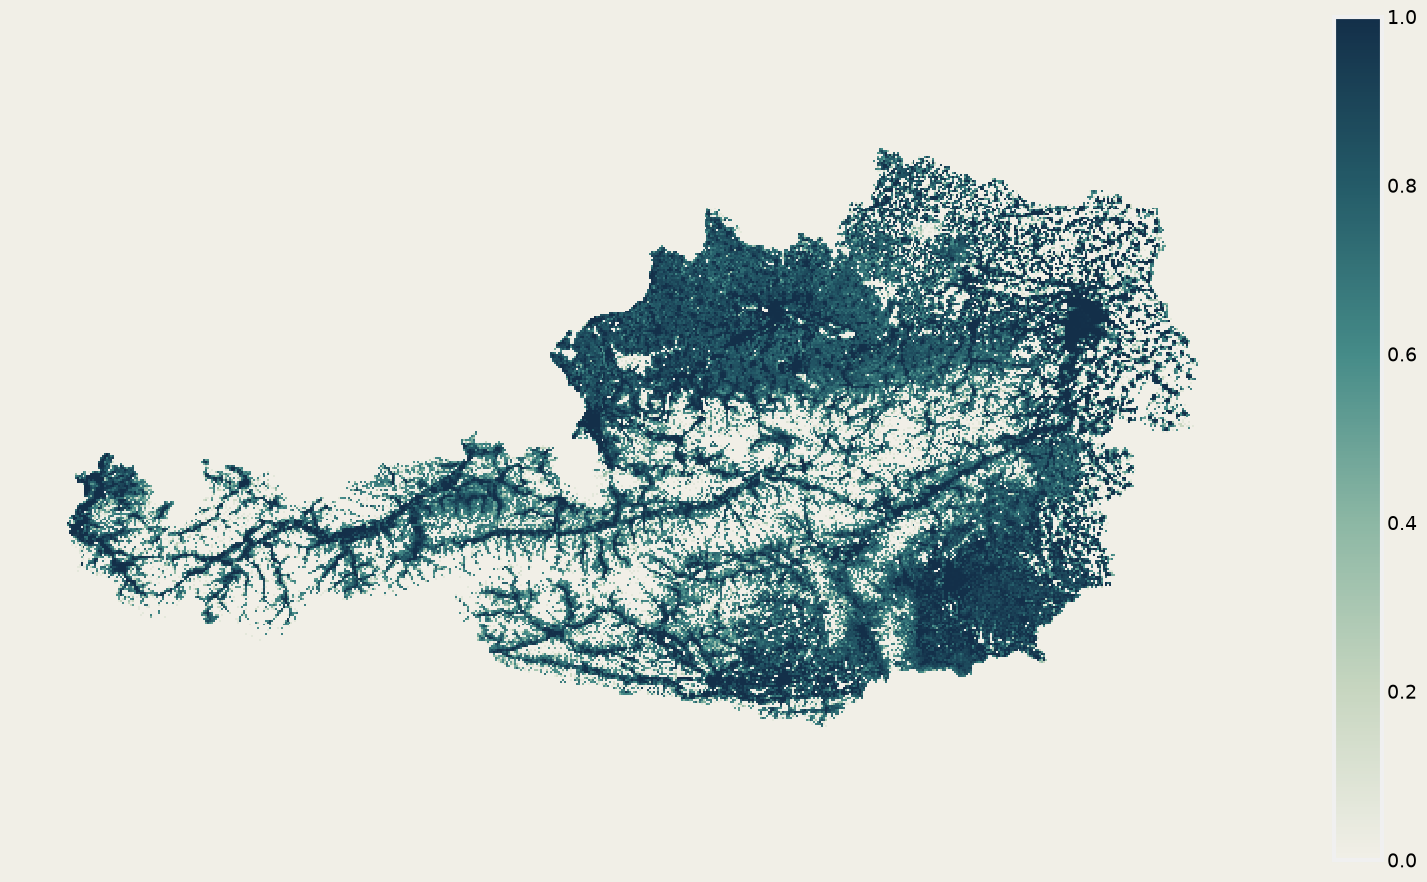

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

colors = [
    "#F1EFE7",
    "#C7D6C0",
    "#8CB7A4",
    "#458B88",
    "#245B68",
    "#132F49"
]

cmap = LinearSegmentedColormap.from_list(
    "urban_rural", colors
)

fig, ax = plt.subplots(figsize=(16, 10))

grid.plot(
    ax=ax,
    column="urbanity",
    cmap=cmap,
    vmin=0,
    vmax=1,
    linewidth=0,
    legend=True
)

ax.set_axis_off()

fig.patch.set_facecolor("#F1EFE7")
ax.set_facecolor("#F1EFE7")

plt.tight_layout()

plt.show()

In [6]:
import requests
import geojson

url = "https://www.statistik.at/gs-open/GEODATA/ows"
params = dict(
    service="WFS",
    version="2.0.0",
    request="GetFeature",
    typeNames="GEODATA:STATISTIK_AUSTRIA_RASTER_L000250",
    outputFormat="application/json",
    srsName="EPSG:31287"
)
r = requests.get(url, params=params)
geodata = geojson.loads(r.content)

In [8]:
data = gpd.GeoDataFrame.from_features(geodata, crs="EPSG:31287")

In [10]:
data.to_file("data/raster_250m.gpkg", layer="raster250m", driver="GPKG")

In [11]:
import geopandas as gpd

grid = gpd.read_file(
    "data/raster_250m.gpkg",
    layer="raster250m"
)

grid = grid.to_crs(31287)

print(grid.shape)
print(grid.columns)

(1000000, 4)
Index(['cellcode', 'code_su', 'code_inspire', 'geometry'], dtype='str')


In [12]:
buildings = buildings.to_crs(grid.crs)

grid = grid.reset_index(drop=True)
grid["grid_id"] = grid.index

joined = gpd.sjoin(
    buildings,
    grid[["grid_id", "geometry"]],
    how="inner",
    predicate="within"
)

stats = joined.groupby("grid_id").agg(
    n_buildings=("grid_id", "size"),
    nn_mean=("nn_distance", "mean"),
    nn_median=("nn_distance", "median")
)

grid = grid.join(stats, on="grid_id")

grid["n_buildings"] = (
    grid["n_buildings"].fillna(0).astype(int)
)

grid["building_density"] = (
        grid["n_buildings"] * 16
)

In [17]:
grid = gpd.read_file("data/buildings_grid.gpkg")

occupied = grid["n_buildings"] > 0


def normalize(series):
    q05 = series.quantile(0.05)
    q95 = series.quantile(0.95)

    if q95 <= q05:
        return series * 0

    return ((series - q05) / (q95 - q05)).clip(0, 1)


grid["density_score"] = 0.0
grid["coverage_score"] = 0.0
grid["proximity_score"] = 0.0

grid.loc[occupied, "density_score"] = normalize(
    np.log1p(grid.loc[occupied, "building_density"])
)

grid.loc[occupied, "coverage_score"] = normalize(
    grid.loc[occupied, "building_coverage"]
)

valid_nn = occupied & grid["nn_median"].notna()

grid.loc[valid_nn, "proximity_score"] = (
        1 - normalize(grid.loc[valid_nn, "nn_median"])
)

grid["urbanity"] = (
        0.40 * grid["density_score"]
        + 0.35 * grid["coverage_score"]
        + 0.25 * grid["proximity_score"]
)


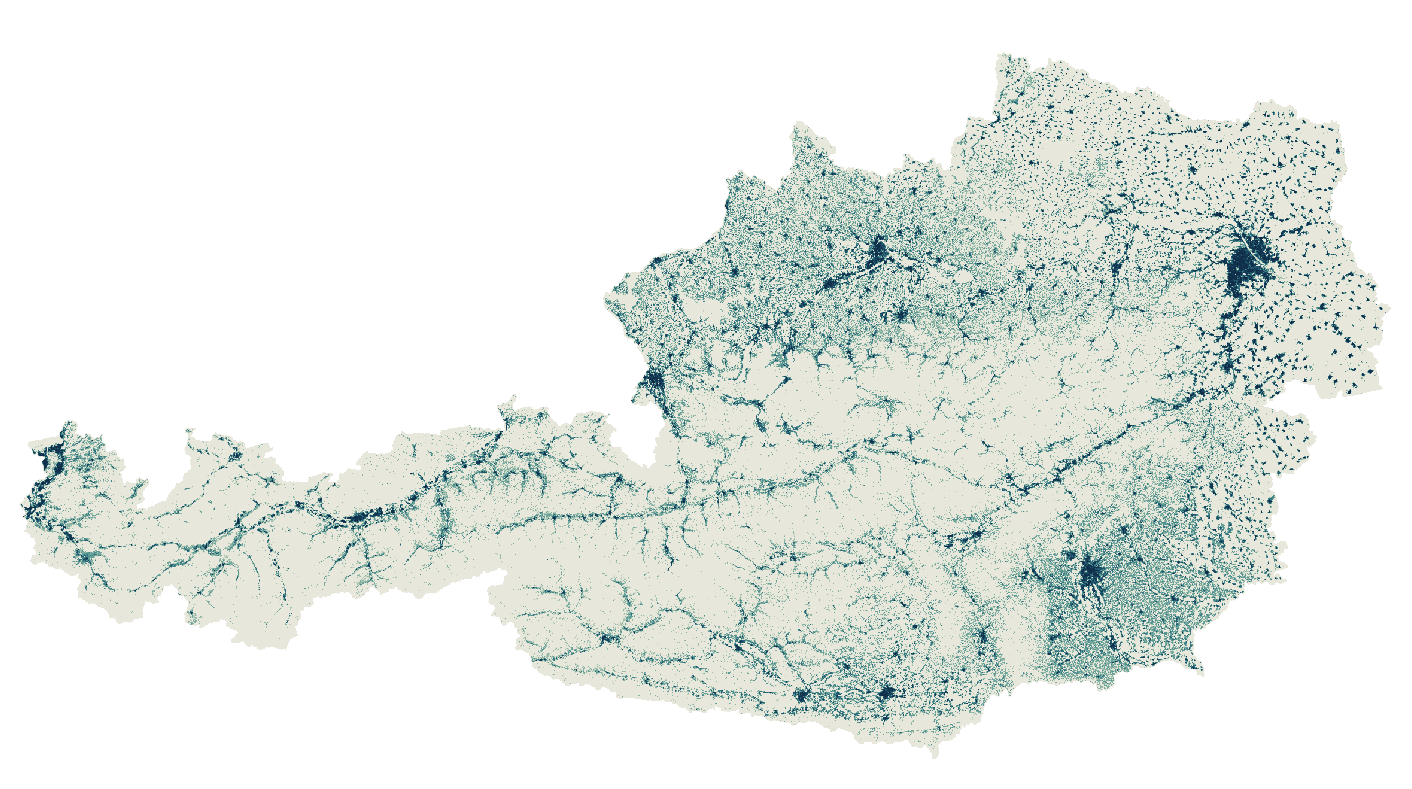

In [23]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from rasterio.transform import array_bounds, from_origin
from rasterio.warp import Resampling, calculate_default_transform, reproject

colors = [
    "#E8E7DC",
    "#C2D1BB",
    "#91B9AA",
    "#5D9B96",
    "#347481",
    "#1D526B",
    "#102E49"
]

cmap = LinearSegmentedColormap.from_list(
    "urban_rural", colors
)

# --------------------------------------------------
# Schnelle Darstellung: Raster statt 1,35 Mio. Polygone
# --------------------------------------------------
# Das 250-m-Raster von Statistik Austria liegt in EPSG:3035 exakt auf
# 250-m-Kanten. Dort wird jede Zelle zu einem Pixel eines Arrays.
RES = 250

centroids = grid.to_crs(3035).geometry.centroid
col = np.floor(centroids.x / RES).astype(int).to_numpy()
row = np.floor(centroids.y / RES).astype(int).to_numpy()

col0, row1 = col.min(), row.max()
urbanity = np.full(
    (row1 - row.min() + 1, col.max() - col0 + 1),
    np.nan,
    dtype="float32"
)
urbanity[row1 - row, col - col0] = grid["urbanity"].to_numpy()

src_transform = from_origin(col0 * RES, (row1 + 1) * RES, RES, RES)
height, width = urbanity.shape

# Array nach EPSG:31287 umprojizieren, damit die Karte gleich aussieht
dst_transform, dst_width, dst_height = calculate_default_transform(
    3035, 31287, width, height,
    *array_bounds(height, width, src_transform)
)
urbanity_31287 = np.full((dst_height, dst_width), np.nan, dtype="float32")

reproject(
    urbanity,
    urbanity_31287,
    src_transform=src_transform,
    src_crs=3035,
    dst_transform=dst_transform,
    dst_crs=31287,
    resampling=Resampling.nearest,
    src_nodata=np.nan,
    dst_nodata=np.nan
)

left, bottom, right, top = array_bounds(dst_height, dst_width, dst_transform)

fig, ax = plt.subplots(figsize=(16, 10))

ax.imshow(
    urbanity_31287,
    extent=(left, right, bottom, top),
    cmap=cmap,
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

ax.set_axis_off()

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#F5F2E9")

plt.savefig(
    "maps/map09.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()